# Chapter 20 · Trees and finite differences: interactive demos

Companion to Chapter 20 of the [MFE 230D lecture notes](https://gennaroalberto.github.io/mfe230d-derivatives/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/mfe230d-derivatives/blob/main/code/notebooks/20-grids.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

The running example is the course's test case $S_0=K=100$, $T=1$, $r=1\%$, $y=2\%$, $\sigma=20\%$ (call $7.36429$).
Everything here is deterministic: trees and grids involve no random numbers.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/mfe230d-derivatives#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from mfe230d import bs
from mfe230d import grids as G
from mfe230d.style import COBALT, GOLD, GREY, INK, use_style

use_style()
GREEN, PURPLE = "#1BAF7A", "#6250D6"
P = bs.TEST_CASE

## 1. The CRR oscillation and better trees

Proposition 20.2: the CRR error of a call is of order $1/n$, but $n(C_n-C)=A+B\theta_n(1-\theta_n)+o(1)$, where
$\theta_n$ is the position of $\log K$ between two terminal nodes, so it wobbles with $n$. The left panel shows
$n(C_n-C)$ and the oscillating part with the coefficient $B$ of Proposition 20.2 (and $A$ fitted); the right panel
compares the absolute errors of CRR, the smoothed BBS tree, its extrapolation BBSR and the Leisen–Reimer tree.

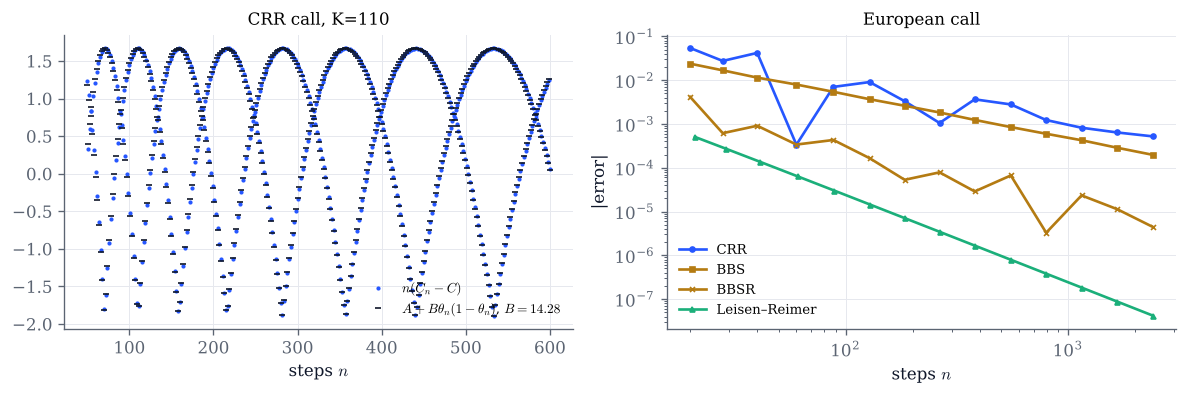

In [2]:
def trees(K=110.0, sigma=0.2, T=1.0, n_max=600):
    S, r, y = P["S"], P["r"], P["y"]
    c = float(bs.call(S, K, T, r, y, sigma))
    ns = np.arange(50, n_max + 1)
    e = np.array([n * (G.binomial_european(S, K, T, r, y, sigma, int(n)) - c) for n in ns])
    th = np.array([G.crr_strike_offset(S, K, T, sigma, int(n)) for n in ns])
    B = G.crr_oscillation_coefficient(S, K, T, r, y, sigma)
    A = float(np.mean(e[len(e) // 2:] - B * th[len(e) // 2:] * (1 - th[len(e) // 2:])))
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(ns, e, ".", ms=3, color=COBALT, label="$n(C_n-C)$")
    ax.plot(ns, A + B * th * (1 - th), "_", ms=4, color=INK, label=rf"$A+B\theta_n(1-\theta_n)$, $B={B:.2f}$")
    ax.set(xlabel="steps $n$", title=f"CRR call, K={K:g}")
    ax.legend(fontsize=8)
    n4 = np.unique(np.round(np.geomspace(20, 4 * n_max, 14) / 4).astype(int) * 4)
    for name, f, nn, col, mk in (
            ("CRR", lambda n: G.binomial_european(S, K, T, r, y, sigma, n), n4, COBALT, "o"),
            ("BBS", lambda n: G.binomial_european(S, K, T, r, y, sigma, n, smooth=True), n4, GOLD, "s"),
            ("BBSR", lambda n: G.bbsr(S, K, T, r, y, sigma, n, "call", "european"), n4, GOLD, "x"),
            ("Leisen–Reimer", lambda n: G.binomial_european(S, K, T, r, y, sigma, n, method="lr"), n4 + 1, GREEN, "^")):
        bx.loglog(nn, [abs(f(int(n)) - c) for n in nn], mk + "-", ms=3, color=col, label=name)
    bx.set(xlabel="steps $n$", ylabel="|error|", title="European call")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

trees()

In [3]:
# Explore: at K = S0 the two parities of n give two smooth sequences; away from the money theta_n wanders.
interact(trees,
         K=FloatSlider(value=110, min=70, max=140, step=1, continuous_update=False, description="K"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="sigma"),
         T=FloatSlider(value=1.0, min=0.1, max=3.0, step=0.1, continuous_update=False, description="T"),
         n_max=IntSlider(value=600, min=200, max=2000, step=100, continuous_update=False, description="n max"));

## 2. Stability and the Crank–Nicolson gamma

Theorem 20.6: the explicit scheme is stable if and only if $\lambda=\sigma^2k/(2h^2)\le\tfrac12$; Crank–Nicolson is
stable for every $\lambda$ but positive only for $\lambda\le\tfrac32$ on the infinite grid and $\lambda\le4-2\sqrt2\approx1.17$ on a finite
one (for the heat equation, Remark 20.7). Left: the error of the explicit
scheme's prices at $t=0$ for a $\lambda$ of your choice (just above $\tfrac12$ a sawtooth grows from the kink). Right:
the gamma of the test-case call from Crank–Nicolson with $N$ time steps, with and without Rannacher's start.

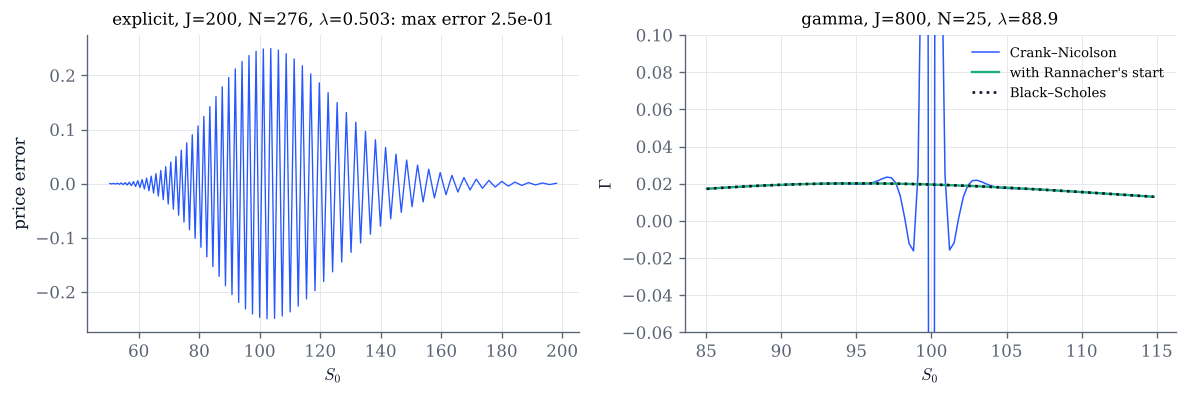

In [4]:
def stability(lam=0.505, J=200, N_cn=25, J_cn=800):
    S, K, T, r, y, sig = (P[k] for k in ("S", "K", "T", "r", "y", "sigma"))
    h = 12 * sig / J
    N = int(np.ceil(T * 0.5 * sig**2 / (lam * h * h)))
    ex = G.fd_solve(S, K, T, r, y, sig, J, N, theta=0.0)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    sel = (ex["s"] > 50) & (ex["s"] < 200)
    err = ex["V"][sel] - bs.call(ex["s"][sel], K, T, r, y, sig)
    ax.plot(ex["s"][sel], err, color=COBALT, lw=0.8)
    ax.set(xlabel="$S_0$", ylabel="price error",
           title=f"explicit, J={J}, N={N}, $\\lambda$={ex['lam']:.3f}: max error {np.max(np.abs(err)):.1e}")
    a = G.fd_greeks(G.fd_solve(S, K, T, r, y, sig, J_cn, N_cn, theta=0.5))
    b = G.fd_greeks(G.fd_solve(S, K, T, r, y, sig, J_cn, N_cn, theta=0.5, rannacher=2))
    s2 = (a["s"] > 85) & (a["s"] < 115)
    lam_cn = 0.5 * sig**2 * (T / N_cn) / (12 * sig / J_cn) ** 2
    bx.plot(a["s"][s2], a["gamma"][s2], color=COBALT, lw=0.9, label="Crank–Nicolson")
    bx.plot(b["s"][s2], b["gamma"][s2], color=GREEN, lw=1.4, label="with Rannacher's start")
    bx.plot(a["s"][s2], bs.greeks(a["s"][s2], K, T, r, y, sig)["gamma"], ":", color=INK, label="Black–Scholes")
    bx.set(xlabel="$S_0$", ylabel="$\\Gamma$", ylim=(-0.06, 0.1), title=f"gamma, J={J_cn}, N={N_cn}, $\\lambda$={lam_cn:.1f}")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

stability()

In [5]:
# Explore: lambda just below and above 1/2; fewer Crank-Nicolson steps mean a larger lambda and a worse gamma.
interact(stability,
         lam=FloatSlider(value=0.505, min=0.45, max=0.55, step=0.001, readout_format=".3f", continuous_update=False, description="lambda"),
         J=IntSlider(value=200, min=50, max=400, step=50, continuous_update=False, description="J explicit"),
         N_cn=IntSlider(value=25, min=5, max=800, step=5, continuous_update=False, description="N (CN)"),
         J_cn=IntSlider(value=800, min=200, max=1600, step=200, continuous_update=False, description="J (CN)"));

## 3. How far must the grid reach?

Proposition 20.9: on a domain $D$ the grid prices the option that pays the boundary data $\beta$ when the log price
leaves $D$; the error at the spot is at most $\varepsilon\,\mathbb Q(\vartheta\le T)$, where $\varepsilon$ bounds the error of $\beta$. The plot
shows the truncation error of the Crank–Nicolson price at $S_0$ (the price on $\log S_0\pm m\sigma\sqrt T$ minus the price on
a much wider grid with the same $h$ and $k$) against the half-width $m$, and the bound with the exact exit
probability, for the boundary data of your choice.

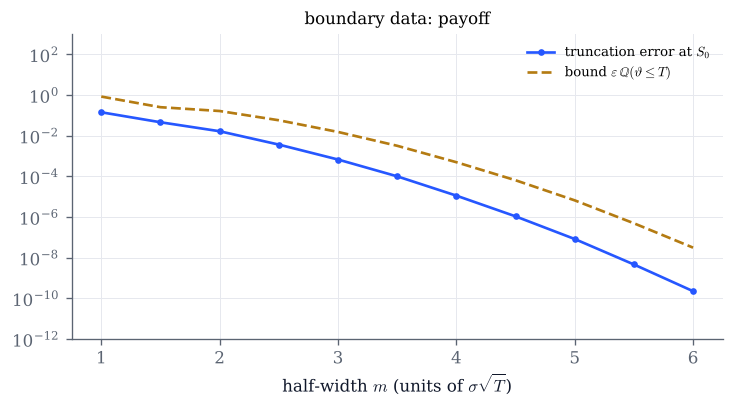

In [6]:
def far_field(bc="payoff", sigma=0.2, T=1.0, K=100.0):
    S, r, y = P["S"], P["r"], P["y"]
    h, N = 12 * sigma * np.sqrt(T) / 800, 200
    Jw = 2 * int(round(10 * sigma * np.sqrt(T) / h))
    wide = G.fd_price(S, K, T, r, y, sigma, Jw, N, rannacher=2, width=Jw * h / (2 * sigma * np.sqrt(T)))
    cond = {"payoff": "payoff", "asymptotic": "asymptotic", "zero": (lambda tau, a, b: (0.0, 0.0))}[bc]
    taus = np.linspace(1e-4, T, 200)
    ms = np.arange(1.0, 6.01, 0.5)
    err, bound = [], []
    for m in ms:
        J = 2 * int(round(m * sigma * np.sqrt(T) / h))
        w = J * h / (2 * sigma * np.sqrt(T))
        err.append(abs(G.fd_price(S, K, T, r, y, sigma, J, N, rannacher=2, width=w, bc=cond) - wide))
        lo, hi = S * np.exp(-w * sigma * np.sqrt(T)), S * np.exp(w * sigma * np.sqrt(T))
        if bc == "asymptotic":
            eps = max(np.max(bs.put(hi, K, taus, r, y, sigma)), np.max(bs.call(lo, K, taus, r, y, sigma)))
        elif bc == "payoff":
            eps = max(np.max(np.abs(bs.call(hi, K, taus, r, y, sigma) - (hi - K))), np.max(bs.call(lo, K, taus, r, y, sigma)))
        else:
            eps = max(np.max(bs.call(hi, K, taus, r, y, sigma)), np.max(bs.call(lo, K, taus, r, y, sigma)))
        bound.append(eps * G.exit_probability(np.log(S), np.log(lo), np.log(hi), T, r, y, sigma))
    err = np.where(np.array(err) > 1e-11, err, np.nan)
    fig, ax = plt.subplots(figsize=(7, 3.3))
    ax.semilogy(ms, err, "o-", ms=3, color=COBALT, label="truncation error at $S_0$")
    ax.semilogy(ms, bound, "--", color=GOLD, label=r"bound $\varepsilon\,\mathbb{Q}(\vartheta\leq T)$")
    ax.set(xlabel=r"half-width $m$ (units of $\sigma\sqrt{T}$)", title=f"boundary data: {bc}", ylim=(1e-12, 1e3))
    ax.legend(fontsize=8)
    plt.show()

far_field()

In [7]:
# Explore: compare the boundary data; the bound is Gaussian in the half-width.
interact(far_field,
         bc=Dropdown(options=["payoff", "asymptotic", "zero"], value="payoff", description="boundary"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="sigma"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         K=FloatSlider(value=100, min=70, max=140, step=5, continuous_update=False, description="K"));

## 4. The American put on a grid

Proposition 20.10: each Crank–Nicolson step becomes a linear complementarity problem, solved by projected SOR,
by the Brennan–Schwartz elimination (valid here: the put exercises at the bottom of the grid) or by the penalty
method. The left panel shows the American and European prices and the exercise boundary at $t=0$; the right panel
the exercise boundary $b(t)$ from the grid and from a CRR tree. The title reports the price, the PSOR sweeps per
step, and the largest residual of the complementarity problem.

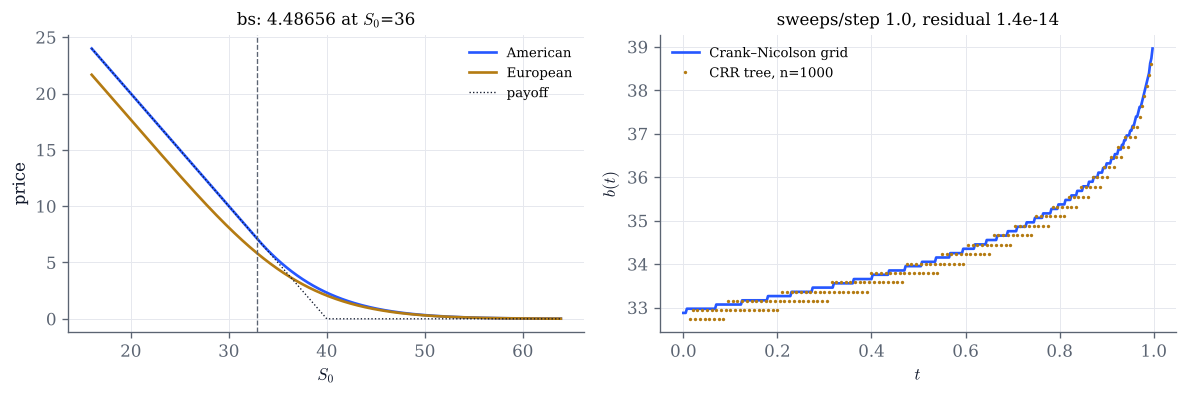

In [8]:
def american(solver="bs", S0=36.0, K=40.0, r=0.06, y=0.0, sigma=0.2, T=1.0, J=800, omega=1.2):
    o = G.fd_solve(S0, K, T, r, y, sigma, J, J // 2, 0.5, "put", "american", rannacher=2, solver=solver,
                   omega=omega, history=True)
    e = G.fd_solve(S0, K, T, r, y, sigma, J, J // 2, 0.5, "put", rannacher=2)
    tr = G.binomial(S0, K, T, r, y, sigma, 1000, "put", "american", history=True)
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 3.4))
    sel = (o["s"] > 0.4 * K) & (o["s"] < 1.6 * K)
    ax.plot(o["s"][sel], o["V"][sel], color=COBALT, label="American")
    ax.plot(e["s"][sel], e["V"][sel], color=GOLD, label="European")
    ax.plot(o["s"][sel], np.maximum(K - o["s"][sel], 0), ":", color=INK, lw=0.8, label="payoff")
    ax.axvline(o["boundary"][-1], color=GREY, lw=0.8, ls="--")
    ax.set(xlabel="$S_0$", ylabel="price", title=f"{solver}: {o['price']:.5f} at $S_0$={S0:g}")
    ax.legend(fontsize=8)
    bx.plot(T - o["tau"], o["boundary"], color=COBALT, label="Crank–Nicolson grid")
    bx.plot(tr["t"][::5], tr["boundary"][::5], ".", ms=2, color=GOLD, label="CRR tree, n=1000")
    bx.set(xlabel="$t$", ylabel="$b(t)$",
           title=f"sweeps/step {o['iterations'] / (J // 2 + 2):.1f}, residual {o['residual']:.1e}")
    bx.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

american()

In [9]:
# Explore: PSOR needs more sweeps as J grows and omega moves away from its best value; r = 0 removes early exercise.
interact(american,
         solver=Dropdown(options=["bs", "psor", "penalty"], value="bs", description="solver"),
         S0=FloatSlider(value=36, min=20, max=60, step=1, continuous_update=False, description="S0"),
         K=FloatSlider(value=40, min=20, max=60, step=1, continuous_update=False, description="K"),
         r=FloatSlider(value=0.06, min=0.0, max=0.15, step=0.01, continuous_update=False, description="r"),
         y=FloatSlider(value=0.0, min=0.0, max=0.1, step=0.01, continuous_update=False, description="y"),
         sigma=FloatSlider(value=0.2, min=0.05, max=0.6, step=0.05, continuous_update=False, description="sigma"),
         T=FloatSlider(value=1.0, min=0.25, max=3.0, step=0.25, continuous_update=False, description="T"),
         J=IntSlider(value=800, min=200, max=1600, step=200, continuous_update=False, description="J"),
         omega=FloatSlider(value=1.2, min=0.8, max=1.9, step=0.05, continuous_update=False, description="omega"));

## Things to try

- In section 1, set $K=S_0=100$ and compare even and odd $n$: on which side of the Black–Scholes price is each
  parity? Then move $K$ slowly away from $S_0$ and watch $\theta_n$ take over.
- In section 1, raise $\sigma$ to $0.5$: does the Leisen–Reimer tree keep its order? Does BBSR?
- In section 2, set $\lambda$ to $0.49$ and then to $0.51$: how many steps does the sawtooth need to become visible, and
  why does it start at the strike?
- In section 2, increase $N$ for Crank–Nicolson until the plain gamma looks right. What value of $\lambda$ is that, and
  how does it compare with the positivity thresholds of Remark 20.7?
- In section 3, compare the "zero" and "asymptotic" boundary data at $m=3$: by how many orders of magnitude does a
  good boundary condition buy you?
- In section 4, set $r=0$ and $y=0$: what happens to the exercise boundary, and why? Then try $y>0$ with $r=0$.